In [2]:
import pandas as pd

In [3]:
df = pd.read_csv('sales.csv')

In [4]:
df.head()

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,CA-2017-152156,08-11-2017,11-11-2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,CA-2017-138688,12-06-2017,16-06-2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,US-2016-108966,11-10-2016,18-10-2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [5]:
df.shape

(9800, 17)

In [6]:
df.columns

Index(['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID',
       'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name',
       'Sales'],
      dtype='object')

In [7]:
df.dtypes

Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code      float64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
dtype: object

In [8]:
df.describe()

,Postal Code,Sales
count,9789.000000,9800.000000
mean,55273.322403,230.769059
std,32041.223413,626.651875
min,1040.000000,0.444000
25%,23223.000000,17.248000
50%,58103.000000,54.490000
75%,90008.000000,210.605000
max,99301.000000,22638.480000


# Data quality assessment

In [9]:
#calculate missing values
df.isnull().sum()

Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64

In [10]:
#duplicate records
df.duplicated().sum()

np.int64(1)

In [11]:
#unique values
df.nunique()

Order ID         4922
Order Date       1230
Ship Date        1326
Ship Mode           4
Customer ID       793
Customer Name     793
Segment             3
Country             1
City              529
State              49
Postal Code       626
Region              4
Product ID       1861
Category            3
Sub-Category       17
Product Name     1849
Sales            5757
dtype: int64

In [12]:
#numerical columns
print(df['Sales'].min())
print(df['Sales'].max())

0.444
22638.48


In [13]:
#total sales
df['Sales'].sum()

np.float64(2261536.7827000003)

In [14]:
#average sales
df['Sales'].mean()

np.float64(230.7690594591837)

# Customer analysis

In [15]:
df['Customer ID'].nunique()

793

In [16]:
df['Segment'].value_counts()

Segment
Consumer       5101
Corporate      2953
Home Office    1746
Name: count, dtype: int64

In [17]:
#unique products
df['Product Name'].nunique()

1849

In [18]:
df['Product Name'].value_counts()

Product Name
Staple envelope                                               47
Staples                                                       46
Easy-staple paper                                             44
Avery Non-Stick Binders                                       20
Staples in misc. colors                                       18
                                                              ..
Avery 484                                                      1
Stride Job 150 Highlighters, Chisel Tip, Assorted Colors       1
Brother MFC-9340CDW LED All-In-One Printer, Copier Scanner     1
Grip Seal Envelopes                                            1
Penpower WorldCard Pro Card Scanner                            1
Name: count, Length: 1849, dtype: int64

In [19]:
df['Product Name'].value_counts().idxmax()

'Staple envelope'

In [21]:
profits = df.groupby('Product Name')['Sales'].sum().sort_values(ascending=False).head(10)

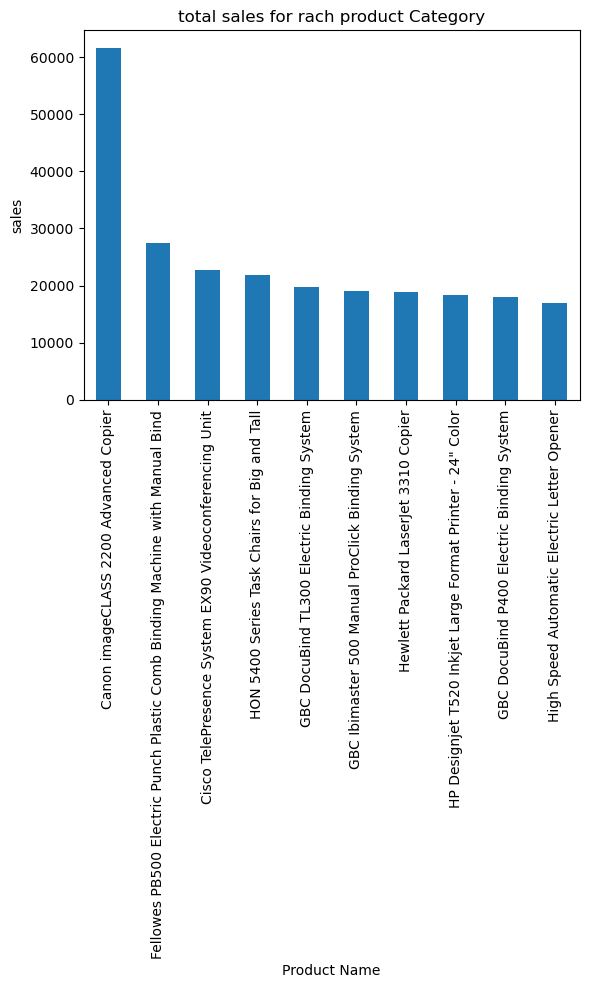

In [22]:
import matplotlib.pyplot as plt
profits.plot(kind='bar')
plt.title('total sales for rach product Category')
plt.ylabel('sales')
plt.show()

# Regional analysis

In [23]:
df['Region'].value_counts()

Region
West       3140
East       2785
Central    2277
South      1598
Name: count, dtype: int64

In [24]:
df.groupby('Region')['Sales'].sum().sort_values(ascending=False)

Region
West       710219.6845
East       669518.7260
Central    492646.9132
South      389151.4590
Name: Sales, dtype: float64

In [26]:
df['State'].value_counts()

State
California              1946
New York                1097
Texas                    973
Pennsylvania             582
Washington               504
Illinois                 483
Ohio                     454
Florida                  373
Michigan                 253
North Carolina           247
Virginia                 224
Arizona                  223
Tennessee                183
Colorado                 179
Georgia                  177
Kentucky                 137
Indiana                  135
Massachusetts            135
Oregon                   122
New Jersey               122
Maryland                 105
Wisconsin                105
Delaware                  93
Minnesota                 89
Connecticut               82
Missouri                  66
Oklahoma                  66
Alabama                   61
Arkansas                  60
Rhode Island              55
Utah                      53
Mississippi               53
South Carolina            42
Louisiana                 41
Nevada  

In [27]:
df.groupby('State')['Sales'].sum().sort_values(ascending=False)

State
California              446306.4635
New York                306361.1470
Texas                   168572.5322
Washington              135206.8500
Pennsylvania            116276.6500
Florida                  88436.5320
Illinois                 79236.5170
Michigan                 76136.0740
Ohio                     75130.3500
Virginia                 70636.7200
North Carolina           55165.9640
Indiana                  48718.4000
Georgia                  48219.1100
Kentucky                 36458.3900
Arizona                  35272.6570
New Jersey               34610.9720
Colorado                 31841.5980
Wisconsin                31173.4300
Tennessee                30661.8730
Minnesota                29863.1500
Massachusetts            28634.4340
Delaware                 27322.9990
Maryland                 23705.5230
Rhode Island             22525.0260
Missouri                 22205.1500
Oklahoma                 19683.3900
Alabama                  19510.6400
Oregon                

# Time-based sales analysis

In [28]:
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)

In [29]:
df.dtypes

Order ID                 object
Order Date       datetime64[ns]
Ship Date                object
Ship Mode                object
Customer ID              object
Customer Name            object
Segment                  object
Country                  object
City                     object
State                    object
Postal Code             float64
Region                   object
Product ID               object
Category                 object
Sub-Category             object
Product Name             object
Sales                   float64
dtype: object

In [30]:
df['year'] = df['Order Date'].dt.year

In [31]:
df['year']

0       2017
1       2017
2       2017
3       2016
4       2016
        ... 
9795    2017
9796    2016
9797    2016
9798    2016
9799    2016
Name: year, Length: 9800, dtype: int32

In [32]:
df.groupby('year')['Sales'].sum().sort_values(ascending=False)

year
2018    722052.0192
2017    600192.5500
2015    479856.2081
2016    459436.0054
Name: Sales, dtype: float64

In [33]:
df['month'] = df['Order Date'].dt.month

In [34]:
df['month']

0       11
1       11
2        6
3       10
4       10
        ..
9795     5
9796     1
9797     1
9798     1
9799     1
Name: month, Length: 9800, dtype: int32

In [35]:
monthly_sales = df.groupby(['month'])['Sales'].sum().sort_values(ascending=True)

Text(0, 0.5, 'Total sales')

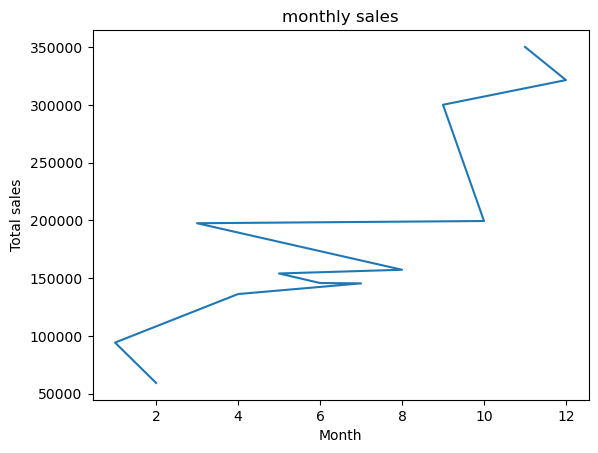

In [36]:
monthly_sales.plot(kind='line')
plt.title('monthly sales')
plt.xlabel('Month')
plt.ylabel('Total sales')

# Customer behaviour analysis

In [37]:
df.groupby('Segment')['Sales'].sum().sort_values(ascending=False)

Segment
Consumer       1.148061e+06
Corporate      6.884941e+05
Home Office    4.249822e+05
Name: Sales, dtype: float64

In [63]:
#Average sales per transaction
df.groupby('Segment')['Sales'].mean()
print(df.groupby('Segment')['Sales'].idxmax())

Segment
Consumer       8153
Corporate      6826
Home Office    2697
Name: Sales, dtype: int64


In [41]:
#Top 10 customers
customers = df.groupby('Customer ID')['Sales'].sum().sort_values(ascending=False).head(10)

In [44]:
Revenue = customers.sum() / df['Sales'].sum() * 100
print(Revenue)

6.8011791882671995


# Shipping analysis

In [45]:
df['Ship Mode'].value_counts() 

Ship Mode
Standard Class    5859
Second Class      1902
First Class       1501
Same Day           538
Name: count, dtype: int64

In [46]:
df['Ship Mode'].value_counts().idxmax()

'Standard Class'

In [47]:
df.groupby('Ship Mode')['Sales'].sum().sort_values(ascending=False)

Ship Mode
Standard Class    1.340831e+06
Second Class      4.499142e+05
First Class       3.455723e+05
Same Day          1.252190e+05
Name: Sales, dtype: float64

In [50]:
#highest value orders
df.groupby('Ship Mode')['Sales'].mean()

Ship Mode
First Class       230.228020
Same Day          232.749143
Second Class      236.547939
Standard Class    228.849856
Name: Sales, dtype: float64

In [51]:
df.groupby('Order ID')['Sales'].sum().sort_values(ascending=False)

Order ID
CA-2015-145317    23661.228
CA-2017-118689    18336.740
CA-2018-140151    14052.480
CA-2018-127180    13716.458
CA-2015-139892    10539.896
                    ...    
US-2018-100209        1.080
US-2015-152723        0.876
CA-2015-112403        0.852
CA-2017-168361        0.836
CA-2018-124114        0.556
Name: Sales, Length: 4922, dtype: float64

In [54]:
df['Ship Date'] = pd.to_datetime(df['Ship Date'], dayfirst=True)

In [55]:
df['year'] = df['Ship Date'].dt.year

In [56]:
df['month'] = df['Ship Date'].dt.month

In [57]:
df.head()

,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,year,month
0,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2017,11
1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,2017,11
2,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2017,6
3,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,2016,10
4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2016,10


In [61]:
shipping_duration = df['Ship Date'] -  df['Order Date']
print(shipping_duration)

0      3 days
1      3 days
2      4 days
3      7 days
4      7 days
        ...  
9795   7 days
9796   5 days
9797   5 days
9798   5 days
9799   5 days
Length: 9800, dtype: timedelta64[ns]


In [62]:
shipping_duration.mean()

Timedelta('3 days 23:04:00.979591836')